# Module 01: Setup, Physical Case Inspection & First Offline Rule-Based Baseline

Welcome to the hands-on **HydroReOpLLM** tutorial curriculum. Following a **Configure → Operate → Execute → Inspect & Plot** progression, this first module takes you from a clean Python environment to a fully verified 365-day offline simulation of **Francis E. Walter Dam** (Lehigh River basin, Pennsylvania) for calendar year **2021**.

| Stage | What You Do | Key HydroReOpLLM API / File |
| --- | --- | --- |
| **1. Configure** | Inspect dam geometry, Lohmann routing reaches, 2021 inflows, and Hanasaki YAML settings | `examples/fe_walter/rule_case.json`, `inflows.csv`, `rule_based.yaml` |
| **2. Operate** | Validate a full-year 2021 experiment plan in a temporary folder (`0` network calls) | `load_settings(..., runtime_root=REPO_ROOT)` |
| **3. Execute** | Run the Hanasaki flood-control rule offline and independently verify mass balance & audit traces | `run_settings(..., allow_network=False)` → `verify_run(..., require_offline=True)` |
| **4. Inspect & Plot** | Convert storage to `ft NGVD29` and visualize 2021 pool elevation alongside release vs. inflow | `reservoir_trajectory.csv`, `study/elevation_storage.csv` |

> **Offline & Clean Workspace Guarantee:** Every simulation in this notebook runs inside `tempfile.TemporaryDirectory()` with `0` network calls, leaving the repository working tree untouched.


## 0. Locate the Repository & Configure Plotting

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "examples" / "fe_walter" / "rule_based.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the HydroReOpLLM repository root. "
        "Launch JupyterLab from the repository root, tutorials/, or a module folder."
    )

REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#d8d8d8",
})

print("Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).")


Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).


## 1. Configure — Inspect `rule_case.json`, `inflows.csv`, and `rule_based.yaml`

HydroReOpLLM strictly separates **physical hydrology and routing** (`rule_case.json` + `inflows.csv`) from **operator policy** (`rule_based.yaml`). Let's inspect F.E. Walter Dam's physical envelope, downstream Lohmann routing network (`FEWalter → USGS01447800 → USGS01449000`), and 2021 daily inflow statistics.


In [2]:
import csv
import json
import yaml
import numpy as np
import pandas as pd

CFS_TO_CMS = 0.028316847
ACFT_TO_M3 = 1233.48183754752

fe_dir = REPO_ROOT / "examples" / "fe_walter"
rule_case = json.loads((fe_dir / "rule_case.json").read_text(encoding="utf-8"))
rule_yaml = yaml.safe_load((fe_dir / "rule_based.yaml").read_text(encoding="utf-8"))

phys = rule_case["network"]["reservoirs"]["FEWalter"]["physical"]
conns = rule_case["network"]["connections"]

print("=== F.E. Walter Physical Reservoir Specification (rule_case.json) ===")
print(f"  Reservoir ID        : {phys['reservoir_id']}")
print(f"  Capacity            : {phys['capacity_m3']:>14,.1f} m3  ({phys['capacity_m3']/ACFT_TO_M3:>9,.1f} ac-ft)")
print(f"  Dead storage        : {phys['dead_storage_m3']:>14,.1f} m3")
print(f"  Initial storage     : {phys['initial_storage_m3']:>14,.1f} m3  ({phys['initial_storage_m3']/ACFT_TO_M3:>9,.1f} ac-ft)")
print(f"  Release bounds      : [{phys['minimum_release_cms']:.1f}, {phys['maximum_release_cms']:.2f}] m3/s "
      f"([0, {phys['maximum_release_cms']/CFS_TO_CMS:,.0f}] cfs)")
print(f"  Timestep dt_seconds : {phys['dt_seconds']:,.0f} s (daily)")
print(f"  Routing reaches     : " + " | ".join(
    f"{c['source']} -> {c['target']} ({len(c['unit_hydrograph'])} UH lags, sum={sum(c['unit_hydrograph']):.6f})"
    for c in conns
))

inflows_df = pd.read_csv(fe_dir / "inflows.csv")
inflows_2021 = inflows_df[
    (inflows_df["date"] >= "2021-01-01") & (inflows_df["date"] <= "2021-12-31")
].copy()
few_in = inflows_2021[inflows_2021["node"] == "FEW_INFLOW"]["local_inflow_cms"]

print("\n=== 2021 Daily Local Inflow Summary (inflows.csv -> FEW_INFLOW) ===")
print(f"  Days                : {len(few_in)}")
print(f"  Mean inflow         : {few_in.mean():.2f} m3/s ({few_in.mean()/CFS_TO_CMS:,.1f} cfs)")
print(f"  Min / Max inflow    : {few_in.min():.2f} / {few_in.max():.2f} m3/s "
      f"({few_in.min()/CFS_TO_CMS:,.1f} / {few_in.max()/CFS_TO_CMS:,.1f} cfs)")
print(f"  Annual inflow vol.  : {few_in.sum() * 86400 / 1e6:.2f} million m3")

agent_cfg = rule_yaml["agents"]["walter_operator"]
print("\n=== Rule-Based Operator Settings (rule_based.yaml) ===")
print(f"  Strategy / Type     : {agent_cfg['strategy']} ({agent_cfg['agent_type']})")
print(f"  Mode / max_calls    : {agent_cfg['mode']} / {rule_yaml['max_calls']}")
print(f"  Rule parameters     : purpose={agent_cfg['rule_parameters']['purpose']}, "
      f"alpha={agent_cfg['rule_parameters']['alpha']}")
print(f"  Auditors            : {agent_cfg['auditors']}")


=== F.E. Walter Physical Reservoir Specification (rule_case.json) ===
  Reservoir ID        : fe_walter
  Capacity            :  135,532,852.3 m3  (109,878.3 ac-ft)
  Dead storage        :            0.0 m3
  Initial storage     :    4,287,715.4 m3  (  3,476.1 ac-ft)
  Release bounds      : [0.0, 283.17] m3/s ([0, 10,000] cfs)
  Timestep dt_seconds : 86,400 s (daily)
  Routing reaches     : FEWalter -> USGS01447800 (21 UH lags, sum=1.000000) | USGS01447800 -> USGS01449000 (2 UH lags, sum=1.000000)

=== 2021 Daily Local Inflow Summary (inflows.csv -> FEW_INFLOW) ===
  Days                : 365
  Mean inflow         : 20.13 m3/s (710.8 cfs)
  Min / Max inflow    : 3.88 / 239.24 m3/s (136.9 / 8,448.7 cfs)
  Annual inflow vol.  : 634.71 million m3

=== Rule-Based Operator Settings (rule_based.yaml) ===
  Strategy / Type     : hanasaki (rule_based)
  Mode / max_calls    : offline / 0
  Rule parameters     : purpose=flood_control, alpha=0.85
  Auditors            : ['release_bounds']


## 2. Operate & 3. Execute — Run 2021 Hanasaki Baseline & Verify Offline

The repository's default `rule_based.yaml` starts on a 7-day quick check (`2021-01-01` to `2021-01-07`). Here we write a clean **365-day (`2021-01-01`–`2021-12-31`)** YAML configuration inside `tempfile.TemporaryDirectory()`, validate it via `load_settings`, run it via `run_settings(..., allow_network=False)`, and independently audit every trace stream and water-balance residual via `verify_run(..., require_offline=True)`.


In [3]:
import tempfile
from llm_reservoir_agent.workflow import load_settings, run_settings
from llm_reservoir_agent.verification import verify_run

def load_fe_walter_curve(path: Path):
    curve = pd.read_csv(path)
    storage_m3 = curve["storage_acft"].to_numpy(dtype=float) * ACFT_TO_M3
    elev_ft = curve["elevation_ft_ngvd29"].to_numpy(dtype=float)
    return storage_m3, elev_ft

curve_storage_m3, curve_elev_ft = load_fe_walter_curve(fe_dir / "study" / "elevation_storage.csv")

with tempfile.TemporaryDirectory(prefix="fe-walter-m01-") as tmp:
    tmp_path = Path(tmp)
    out_dir = tmp_path / "fe-walter-rule-2021"
    cfg = dict(rule_yaml)
    cfg["case"] = str((fe_dir / "rule_case.json").resolve())
    cfg["run_id"] = "fe-walter-rule-2021-tutorial"
    cfg["output"] = str(out_dir)
    cfg["start_date"] = "2021-01-01"
    cfg["end_date"] = "2021-12-31"
    cfg["extensions"] = {"hanasaki": str((fe_dir / "study" / "rule" / "__init__.py").resolve())}
    cfg["agents"] = {
        "walter_operator": {
            **rule_yaml["agents"]["walter_operator"],
            "rule_parameters": {
                **rule_yaml["agents"]["walter_operator"]["rule_parameters"],
                "inflow_statistics_file": str((fe_dir / "rule_statistics.json").resolve()),
            },
        }
    }
    cfg_path = tmp_path / "rule_based_2021.yaml"
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding="utf-8")

    # Stage 2: Validate plan offline
    settings = load_settings(cfg_path, runtime_root=REPO_ROOT)
    print("=== Checked Plan (load_settings) ===")
    print(f"  Window              : {settings.report['start_date']} to {settings.report['end_date']} ({settings.report['days']} days)")
    print(f"  Planned LLM calls   : {settings.report['planned_llm_calls']} (network_calls={settings.report['network_calls']})")
    print(f"  Agent types / rules : {settings.report['agent_types']} / {settings.report['agent_rules']}")

    # Stage 3: Execute & independently verify offline
    records, run_summary = run_settings(settings, allow_network=False, runtime_root=REPO_ROOT)
    verification = verify_run(out_dir, require_offline=True)

    # Read exported CSV outputs before temporary directory cleans up
    traj_df = pd.read_csv(out_dir / "reservoir_trajectory.csv")
    flows_df = pd.read_csv(out_dir / "network_flows.csv")
    balance_df = pd.read_csv(out_dir / "network_balance.csv")
    output_names = sorted(p.name for p in out_dir.iterdir() if p.is_file())

traj_df["date"] = pd.to_datetime(traj_df["date"].str.slice(0, 10))
traj_df["elev_ft"] = np.interp(traj_df["storage_end_m3"], curve_storage_m3, curve_elev_ft)
traj_df["inflow_cfs"] = traj_df["inflow_cms"] / CFS_TO_CMS
traj_df["release_cfs"] = traj_df["total_outflow_cms"] / CFS_TO_CMS

initial_elev = float(np.interp(phys["initial_storage_m3"], curve_storage_m3, curve_elev_ft))
final_storage = float(traj_df["storage_end_m3"].iloc[-1])
final_elev = float(traj_df["elev_ft"].iloc[-1])

print("\n=== Independent Verification Result (verify_run, require_offline=True) ===")
print(f"  Verification status : {verification['status']}")
print(f"  Days verified       : {verification['days']} ({verification['date_start']} -> {verification['date_end']})")
print(f"  Network calls       : {verification['observed_network_calls']}")
print(f"  Audit counts        : {verification['audit_counts']}")
print(f"  Max reservoir resid.: {verification['max_reservoir_balance_residual_m3']:.3e} m3")
print(f"  Max system residual : {verification['max_system_balance_residual_m3']:.3e} m3")
print(f"  Max routing diff    : {verification['max_routing_difference_cms']:.3e} m3/s")
print(f"  Initial storage     : {phys['initial_storage_m3']:>14,.1f} m3  ({initial_elev:.2f} ft NGVD29)")
print(f"  Final storage       : {final_storage:>14,.1f} m3  ({final_elev:.2f} ft NGVD29)")
print(f"  Peak elevation      : {traj_df['elev_ft'].max():.2f} ft on {traj_df.loc[traj_df['elev_ft'].idxmax(), 'date'].strftime('%Y-%m-%d')}")
print(f"  Exported artifacts  : {', '.join(output_names)}")


=== Checked Plan (load_settings) ===
  Window              : 2021-01-01 to 2021-12-31 (365 days)
  Planned LLM calls   : 0 (network_calls=0)
  Agent types / rules : {'walter_operator': 'rule_based'} / {'walter_operator': 'hanasaki'}



=== Independent Verification Result (verify_run, require_offline=True) ===
  Verification status : PASS
  Days verified       : 365 (2021-01-01 -> 2021-12-31)
  Network calls       : 0
  Audit counts        : {'PASS': 365}
  Max reservoir resid.: 1.350e-08 m3
  Max system residual : 9.127e-08 m3
  Max routing diff    : 2.842e-14 m3/s
  Initial storage     :    4,287,715.4 m3  (1312.43 ft NGVD29)
  Final storage       :  115,202,924.5 m3  (1440.39 ft NGVD29)
  Peak elevation      : 1440.39 ft on 2021-10-16
  Exported artifacts  : audit.jsonl, backend_events.jsonl, decisions.jsonl, experiment.json, index.json, network_balance.csv, network_flows.csv, odd_llm_manifest.json, physics.jsonl, progress.json, reach_volume_trace.json, reservoir_trajectory.csv, summary.json


## 4. Inspect & Plot Results — 2021 Pool Elevation and Release vs. Inflow

Let's inspect the quarterly hydrological balance of the Hanasaki flood-control baseline and plot a 2-panel diagnostic figure comparing **pool elevation (`ft NGVD29`)** against the seasonal operating benchmarks (`1,300 ft` winter normal pool and `1,370 ft` summer recreation pool) and **daily release vs. inflow (`cfs`)**.


=== 2021 Quarterly Hanasaki Baseline Summary ===
         mean_inflow_cfs  mean_release_cfs  max_release_cfs  end_elev_ft  max_elev_ft
quarter                                                                              
2021 Q1            671.3             494.7           4369.1       1390.6       1390.6
2021 Q2            430.4             340.3           2154.1       1408.0       1408.0
2021 Q3            942.2             738.6           6580.8       1437.3       1437.3
2021 Q4            795.2             767.9           3554.3       1440.4       1440.4


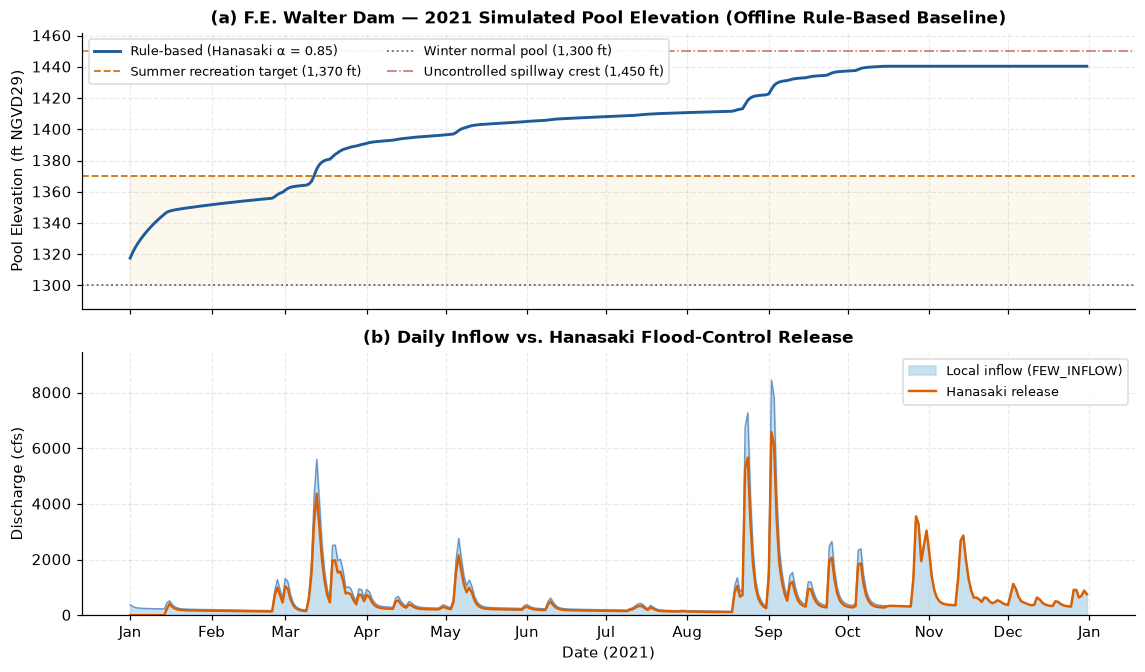

In [4]:
import matplotlib.dates as mdates

traj_df["quarter"] = "2021 Q" + traj_df["date"].dt.quarter.astype(str)
q_summary = traj_df.groupby("quarter").agg(
    mean_inflow_cfs=("inflow_cfs", "mean"),
    mean_release_cfs=("release_cfs", "mean"),
    max_release_cfs=("release_cfs", "max"),
    end_elev_ft=("elev_ft", "last"),
    max_elev_ft=("elev_ft", "max"),
)
print("=== 2021 Quarterly Hanasaki Baseline Summary ===")
print(q_summary.round(1).to_string())

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.05, 1.0]}
)

# Panel (a): Pool elevation
ax1.plot(traj_df["date"], traj_df["elev_ft"], color="#1f5a99", lw=1.9, label="Rule-based (Hanasaki α = 0.85)")
ax1.axhline(1370.0, color="#c97a16", ls="--", lw=1.2, label="Summer recreation target (1,370 ft)")
ax1.axhline(1300.0, color="#5f6b7a", ls=":", lw=1.2, label="Winter normal pool (1,300 ft)")
ax1.axhline(1450.0, color="#b83232", ls="-.", lw=1.0, alpha=0.75, label="Uncontrolled spillway crest (1,450 ft)")
ax1.fill_between(
    traj_df["date"], 1300.0, 1370.0, color="#f4d9a6", alpha=0.18, zorder=0
)
ax1.set_ylabel("Pool Elevation (ft NGVD29)")
ax1.set_title("(a) F.E. Walter Dam — 2021 Simulated Pool Elevation (Offline Rule-Based Baseline)")
ax1.set_ylim(1285, 1462)
ax1.legend(loc="upper left", ncol=2, fontsize=8.5)

# Panel (b): Daily inflow vs. release
ax2.fill_between(
    traj_df["date"], 0, traj_df["inflow_cfs"], color="#9ecae1", alpha=0.55, label="Local inflow (FEW_INFLOW)"
)
ax2.plot(traj_df["date"], traj_df["inflow_cfs"], color="#4f81bd", lw=0.9, alpha=0.8)
ax2.plot(traj_df["date"], traj_df["release_cfs"], color="#d95f02", lw=1.6, label="Hanasaki release")
ax2.set_ylabel("Discharge (cfs)")
ax2.set_xlabel("Date (2021)")
ax2.set_title("(b) Daily Inflow vs. Hanasaki Flood-Control Release")
ax2.set_ylim(0, max(traj_df["inflow_cfs"].max(), traj_df["release_cfs"].max()) * 1.12)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.legend(loc="upper right", fontsize=8.8)

fig.tight_layout()
plt.show()


## Key Takeaways & Next Step

- **Strict mass balance & auditability:** `verify_run(..., require_offline=True)` confirmed `PASS` across all 365 days with `0` network calls and near-zero floating-point water-balance residuals (`< 1e-8 m³`).
- **Why a pure flood-control rule struggles with seasonal targets:** Because Hanasaki releases scale with long-term mean inflow and current storage ratio without seasonal rule-curve awareness, the reservoir climbs steadily above `1,370 ft` into the flood-control zone instead of holding `1,300 ft` in winter and `1,370 ft` in summer.
- **CLI Equivalent:**
  ```sh
  reservoir-experiment check examples/fe_walter/rule_based.yaml
  reservoir-experiment run examples/fe_walter/rule_based.yaml
  reservoir-experiment verify runs/fe-walter-rule-based --require-offline
  ```
- **Next Module →** [`Module 02: LLM Prompt & Operational Knowledge Design`](../02_prompt_and_knowledge_design/README.md) compares **Without operational knowledge** (`seasonal_target.yaml`) vs. **With operational knowledge** (`dkp.yaml`) against USGS observations.
